In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib

In [2]:
df = pd.read_csv("Student_Performance.csv")
df.head(10)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
5,3,78,No,9,6,61.0
6,7,73,Yes,5,6,63.0
7,8,45,Yes,4,6,42.0
8,5,77,No,8,2,61.0
9,4,89,No,4,0,69.0


In [3]:
df.shape


(10000, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


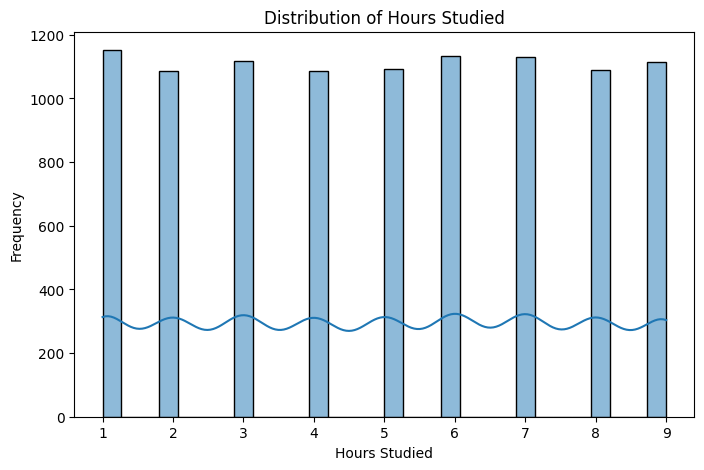

Hours Studied Skewness: -0.0042



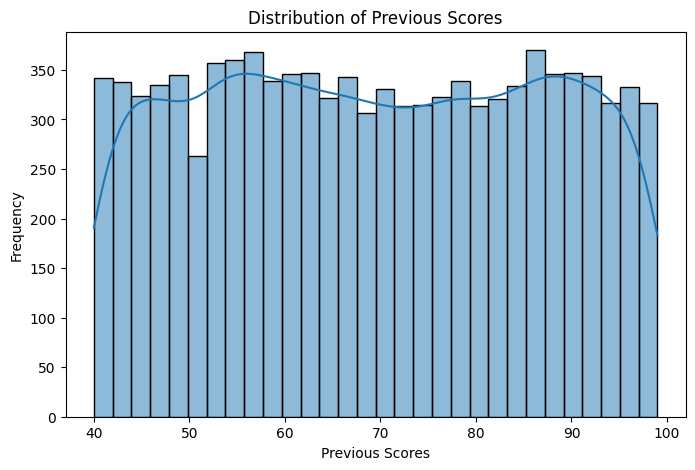

Previous Scores Skewness: 0.0045



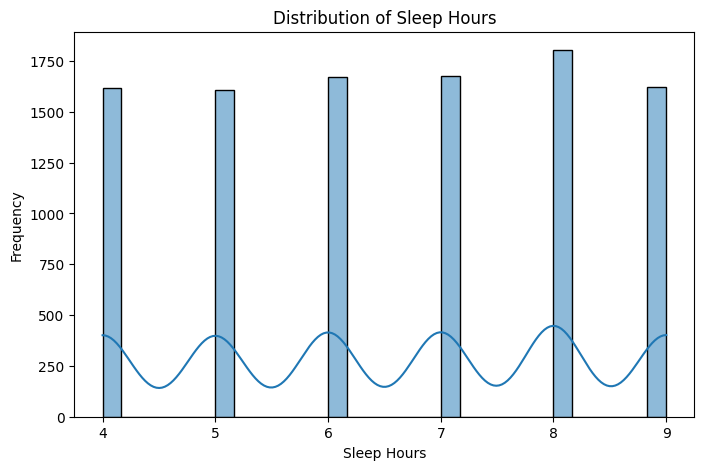

Sleep Hours Skewness: -0.0395



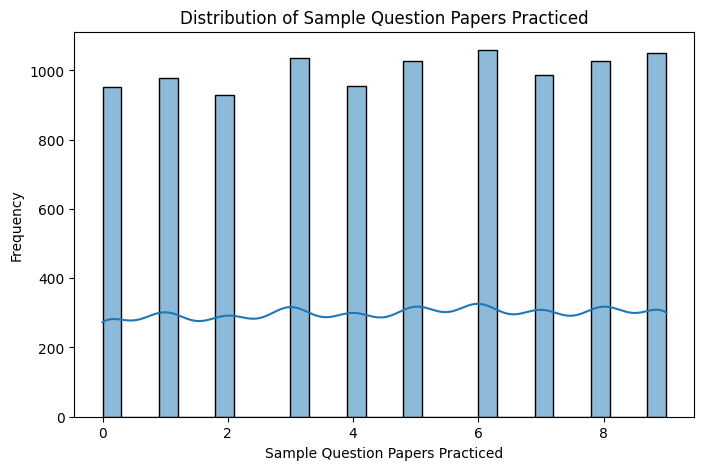

Sample Question Papers Practiced Skewness: -0.0356



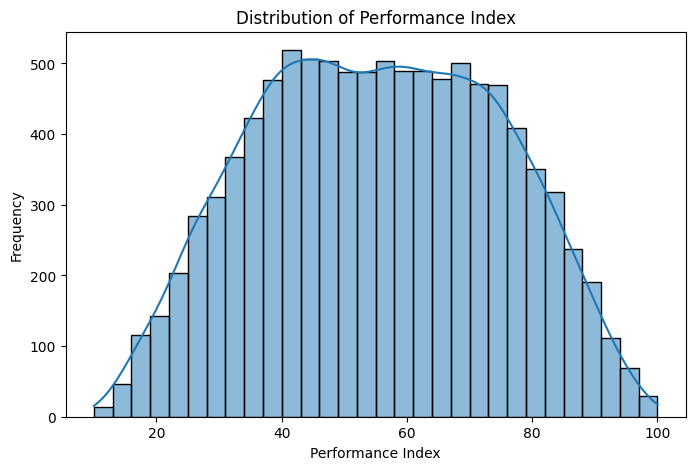

Performance Index Skewness: -0.0017



In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    plt.figure(figsize=(8,5))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
    
    # Print skewness
    skewness = df[col].skew()
    print(f"{col} Skewness: {skewness:.4f}\n")


In [6]:

df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'Yes': 1, 'No': 0})


print(df['Extracurricular Activities'].value_counts())
df.head()


Extracurricular Activities
0    5052
1    4948
Name: count, dtype: int64


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [7]:
df['Study Efficiency'] = df['Hours Studied'] / df['Sleep Hours']
df['Practice Intensity'] = df['Sample Question Papers Practiced'] / df['Hours Studied']
df['Score Improvement Potential'] = df['Previous Scores'] * df['Hours Studied']
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index,Study Efficiency,Practice Intensity,Score Improvement Potential
0,7,99,1,9,1,91.0,0.777778,0.142857,693
1,4,82,0,4,2,65.0,1.000000,0.500000,328
2,8,51,1,7,2,45.0,1.142857,0.250000,408
3,5,52,1,5,2,36.0,1.000000,0.400000,260
4,7,75,0,8,5,66.0,0.875000,0.714286,525


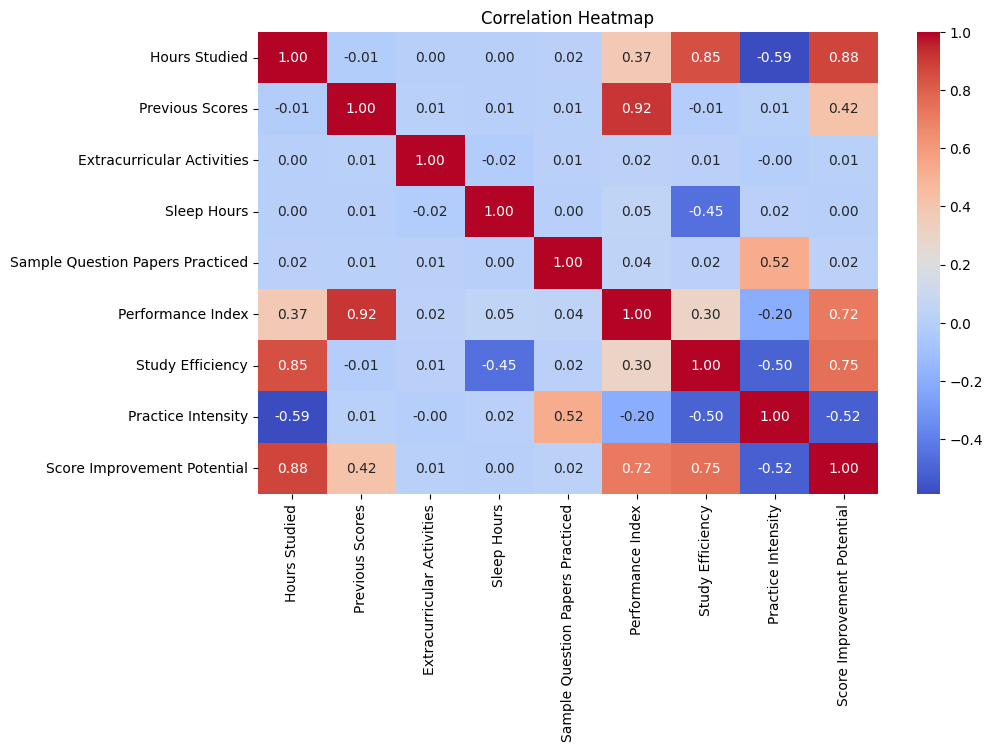

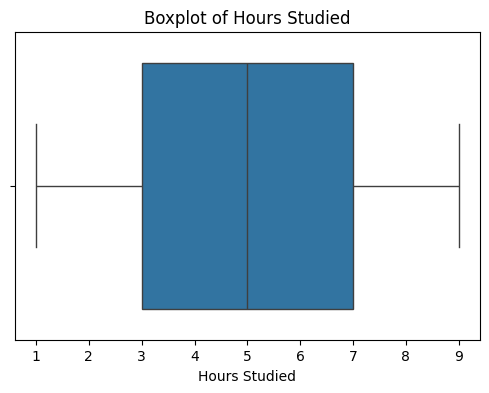

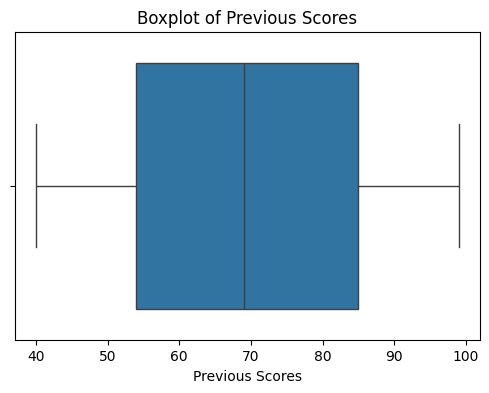

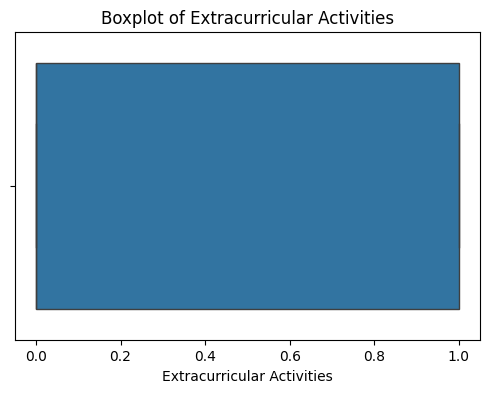

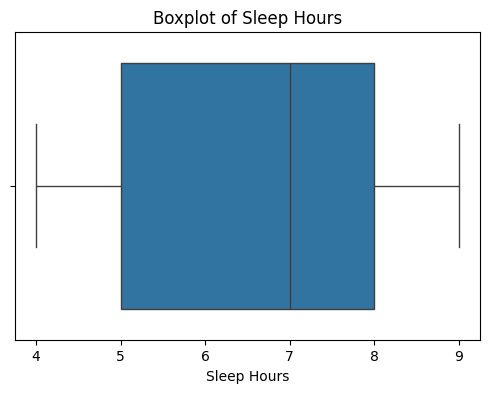

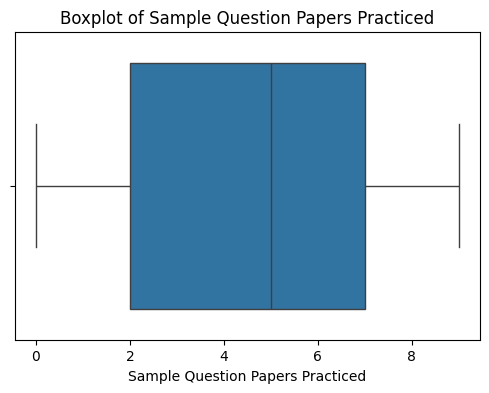

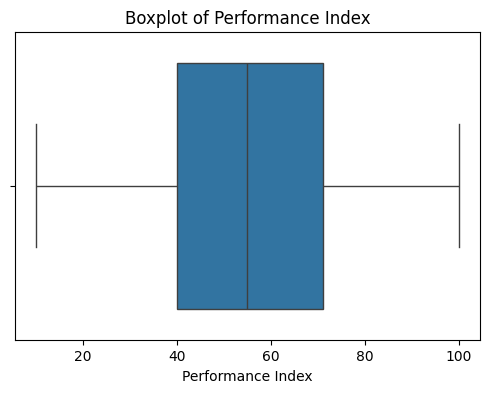

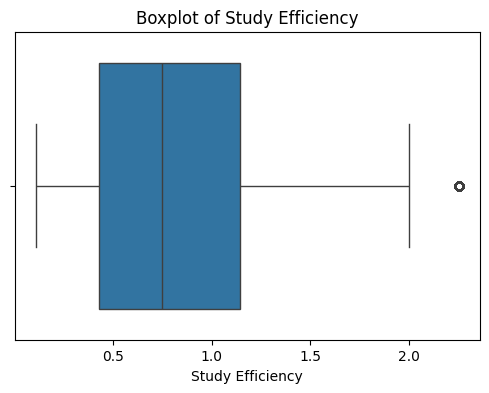

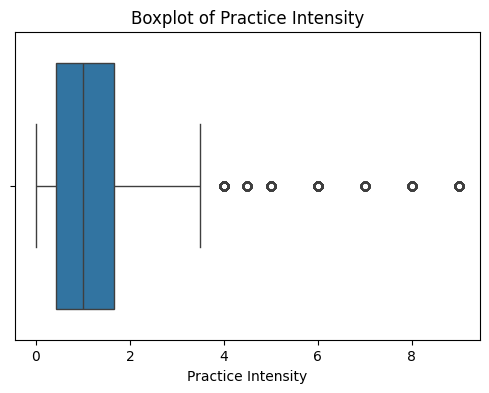

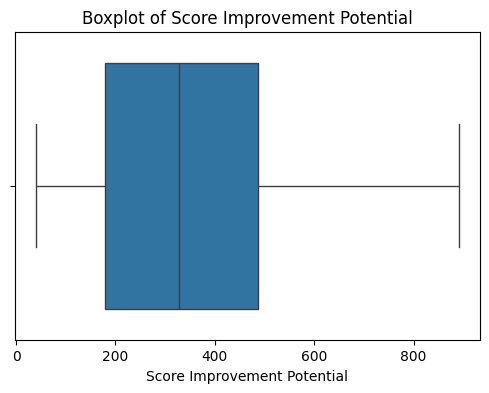

RuntimeError: `lowess=True` requires statsmodels, an optional dependency, to be installed.

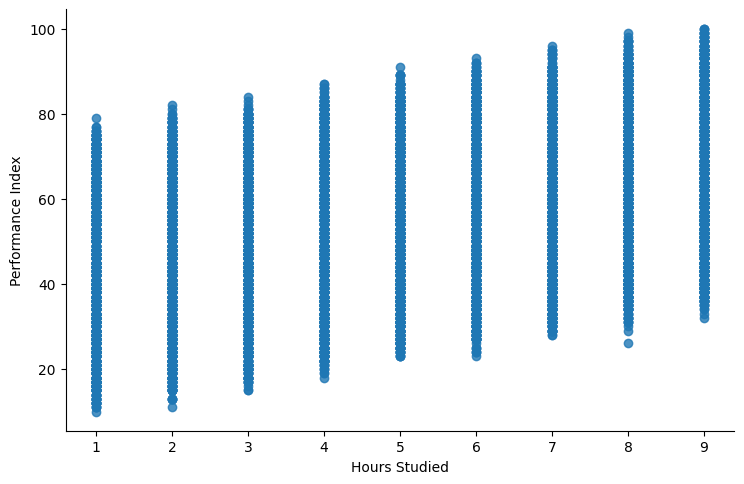

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

numeric_cols = df.select_dtypes(include=['int64','float64']).columns
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

sns.lmplot(x="Hours Studied", y="Performance Index", data=df, lowess=True, height=5, aspect=1.5)
plt.title("Trend: Hours Studied vs Performance Index")
plt.show()

sns.lmplot(x="Sleep Hours", y="Performance Index", data=df, lowess=True, height=5, aspect=1.5)
plt.title("Trend: Sleep Hours vs Performance Index")
plt.show()


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

X = df.drop(columns=['Performance Index'])
y = df['Performance Index']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R²:", r2)


RMSE: 2.019887767658607
R²: 0.9889905276337734
